In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.animation import FuncAnimation
from IPython import display
from tqdm import tqdm
import numpy as np
from scipy.stats import yulesimon, linregress
from scipy.optimize import curve_fit

## Import the data
The data used for the analysis is imported from the `publications_research_year_domain.parquet` file and stored in the `cleaned_papers` dataframe.

In [2]:
DATA = Path('../data/external')
CACHE = DATA / 'cache'
cleaned_papers = pd.read_parquet(DATA / 'papers_cleaned.gencat.parquet')
cleaned_papers = cleaned_papers.drop_duplicates(subset="doi").reset_index(drop=True)


### Formatting the date datasets

In [3]:
cleaned_papers['date'] = pd.to_datetime(cleaned_papers['date'])
print(min(cleaned_papers['date'].dt.year))
print(max(cleaned_papers['date'].dt.year))

1949
2026


In [4]:
#year_df = cleaned_papers[cleaned_papers['date'].dt.year == 2021]
exploded_papers = cleaned_papers.explode('orcidResearchers')
grouped = exploded_papers['orcidResearchers'].value_counts() 
#grouped

In [5]:
vc = grouped.value_counts().sort_index()            # counts per value, ascending x

dif = pd.DataFrame({
    "value": vc.index,
    "count": vc.values,
})
dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
# optional: "fraction >= x" instead of "> x"
dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()

In [6]:
def f(data, rho):
    N = len(data)
    double_sum = 0
    for k in data:
        for j in range(1, k+1):
            double_sum = double_sum + 1 / (rho + j)
    return N / double_sum 

In [7]:
rho_0 = 0 # initial guess
epsilon = 0.00000001 # tolerance

converged = False
while not converged:
    rho_1 = f(grouped.values, rho_0)
    converged = abs(rho_1 - rho_0) < epsilon
    rho_0 = rho_1
    print(rho_1)
mle_rho = rho_1
vc = grouped.value_counts().sort_index()
est_probs = yulesimon.pmf(vc.index, 0.8) # Probabilities

0.3484566629878861
0.4042548213817874
0.4123921703605101
0.413563929308483
0.41373235522894586
0.41375655810450296
0.4137600359382406
0.4137605356836566
0.41376060749368304
0.4137606178119118
0.4137606192952064


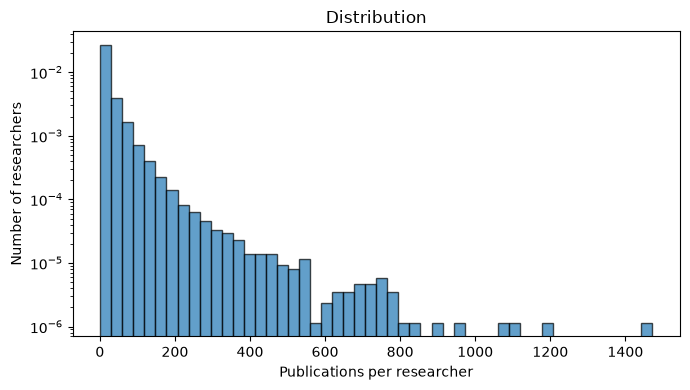

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))

vc = grouped.value_counts().sort_index()

ax.hist(grouped,bins=50, edgecolor='black', density = True, alpha=0.7)
#ax.plot(vc.index,est_probs)
ax.set_title('Distribution')
ax.set_yscale('log')
#ax.set_xscale('log')
ax.set_xlabel('Publications per researcher')
ax.set_ylabel('Number of researchers')
#ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

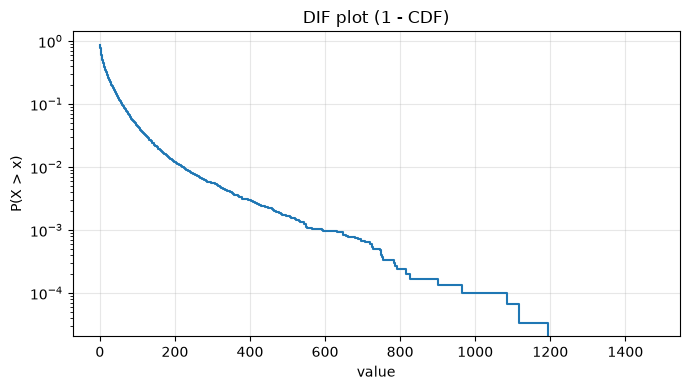

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(dif["value"], dif["surv"])
ax.set_xlabel("value")
ax.set_ylabel("P(X > x)")
ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
#ax.set_xscale("log")
ax.set_yscale("log")
plt.tight_layout()
plt.show()

## Yearly researcher publication distributions

This code calculates the complementary cumulative distribution functions (CCDFs) of researcher publication counts separately for each year.

1. **Yearly filtering:** Selects publications from each year in the dataset.
2. **Researcher expansion:** Uses `explode()` to associate each publication with its individual researchers.
3. **Publication counting:** Calculates the number of publications per researcher and the number of researchers with each publication count.
4. **Cumulative distributions:** Computes the CDF (`cdf`), CCDF (`surv`) and survival probability including the current value (`surv_ge`), representing the fraction of researchers who have published at least a given number of papers.
5. **Data storage:** Stores the publication counts (`papers_y`) and their corresponding survival probabilities (`researchers_y`) for each year, retaining only distributions with more than one distinct publication count.


In [10]:
papers_y = []
researchers_y = []
for year_paper in range(min(cleaned_papers['date'].dt.year),max(cleaned_papers['date'].dt.year)+1):
    year_df = cleaned_papers[cleaned_papers['date'].dt.year == year_paper]
    exploded_papers = year_df.explode('orcidResearchers')
    grouped = exploded_papers['orcidResearchers'].value_counts() 
    vc = grouped.value_counts().sort_index()            # counts per value, ascending x
    
    dif = pd.DataFrame({
        "value": vc.index,
        "count": vc.values,
    })
    dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
    dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
    # optional: "fraction >= x" instead of "> x"
    dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()
    if len(dif["surv_ge"])>1:
        papers_y.append(dif["value"])
        researchers_y.append(dif["surv_ge"])
       # print(year_paper)
#print(len(papers_y))
#print(len(researchers_y))

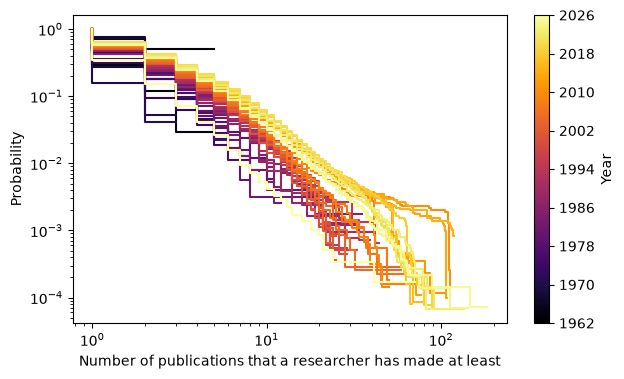

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
cmap1 = plt.get_cmap('inferno')
colors = cmap1(np.linspace(0, 1, len(papers_y)))

for i, (paper, researcher) in enumerate(zip(papers_y, researchers_y)):
    ax.step(paper, researcher, color=colors[i])
ax.set_xlabel("Number of publications that a researcher has made at least")
ax.set_ylabel("Probability")
#ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.set_xscale("log")
ax.set_yscale("log")
yr_min = 1962
yr_max = max(cleaned_papers['date'].dt.year)
norm = plt.Normalize(vmin=yr_min, vmax=yr_max)

sm = plt.cm.ScalarMappable(cmap=cmap1, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('Year')
cbar.set_ticks(range(yr_min,yr_max+1,8))
#cbar.set_ticklabels(fields_labels)
path = Path('../plots/albert/CCDF_per_years.png')
plt.savefig(path, dpi=300, bbox_inches='tight')
plt.show()

In [26]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from pathlib import Path

# Configuration
window = 5
previous_alpha = 0.3
current_alpha = 1.0

# Check data consistency
assert len(papers_y) == len(researchers_y), \
    "papers_y and researchers_y must have the same length"

years = np.sort(cleaned_papers['date'].dt.year.unique())

n_frames = min(len(years), len(papers_y))
years = years[:n_frames]

# Colormap
cmap1 = plt.get_cmap('inferno')
norm = plt.Normalize(vmin=years.min(), vmax=years.max())

# Calculate fixed axis limits using ALL distributions
all_x = np.concatenate([
    np.asarray(papers_y[i]).ravel()
    for i in range(n_frames)
])

all_y = np.concatenate([
    np.asarray(researchers_y[i]).ravel()
    for i in range(n_frames)
])

# Remove invalid values for logarithmic scales
all_x = all_x[np.isfinite(all_x) & (all_x > 0)]
all_y = all_y[np.isfinite(all_y) & (all_y > 0)]

x_min, x_max = all_x.min(), all_x.max()
y_min, y_max = all_y.min(), all_y.max()

# Figure
fig, ax = plt.subplots(figsize=(7, 4))

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap1, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('Year')
cbar.set_ticks(years[::max(1, len(years)//8)])

def update(frame):

    ax.clear()

    ax.set_xlabel(
        "Number of publications that a researcher has made at least"
    )
    ax.set_ylabel("Probability")

    ax.set_xscale("log")
    ax.set_yscale("log")

    # FIXED AXIS LIMITS for every frame
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max+1)

    # Current year + up to 5 previous years
    start = max(0, frame - window)

    for i in range(start, frame + 1):

        year = years[i]
        color = cmap1(norm(year))

        # Current year highlighted
        alpha = current_alpha if i == frame else previous_alpha

        ax.step(
            papers_y[i],
            researchers_y[i],
            color=color,
            alpha=alpha,
            linewidth=1.8 if i == frame else 1.2
        )

    ax.set_title(f"Distribution evolution: {years[frame]}")

    return ax.lines

# Create animation
anim = FuncAnimation(
    fig,
    update,
    frames=n_frames,
    interval=400,
    repeat=True,
    blit=False
)

# Save GIF
output_path = Path('../plots/albert/CCDF_evolution.gif')
output_path.parent.mkdir(parents=True, exist_ok=True)

anim.save(
    output_path,
    writer=PillowWriter(fps=3),
    dpi=150
)

plt.close(fig)

print(f"GIF saved to: {output_path}")


GIF saved to: ..\plots\albert\CCDF_evolution.gif


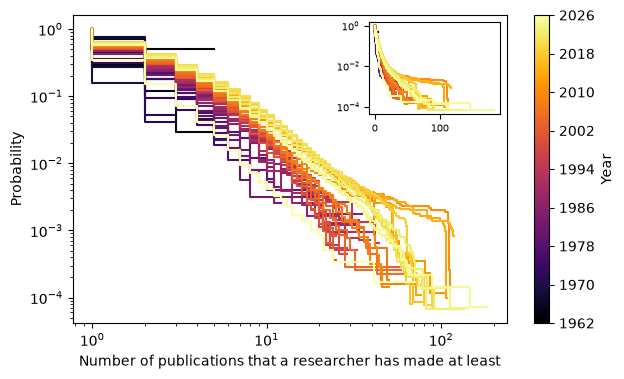

In [13]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

fig, ax = plt.subplots(figsize=(7, 4))

cmap1 = plt.get_cmap('inferno')
colors = cmap1(np.linspace(0, 1, len(papers_y)))

# =====================================================
# Main plot (log-log)
# =====================================================

for i, (paper, researcher) in enumerate(zip(papers_y, researchers_y)):
    ax.step(paper, researcher, color=colors[i])

ax.set_xlabel("Number of publications that a researcher has made at least")
ax.set_ylabel("Probability")

ax.set_xscale("log")
ax.set_yscale("log")

# =====================================================
# Inset plot (linear x-axis, logarithmic y-axis)
# =====================================================

axins = inset_axes(
    ax,
    width="30%",
    height="30%",
    loc="upper right"
)

for i, (paper, researcher) in enumerate(zip(papers_y, researchers_y)):
    axins.step(paper, researcher, color=colors[i])

axins.set_xscale("linear")
axins.set_yscale("log")

#axins.set_xlabel("Publications", fontsize=8)
#axins.set_ylabel("Probability", fontsize=8)

axins.tick_params(axis='both', labelsize=7)

# Optional: restrict inset x-axis
#axins.set_xlim(0, 50)

# =====================================================
# Colorbar (year)
# =====================================================

yr_min = 1962
yr_max = max(cleaned_papers['date'].dt.year)

norm = plt.Normalize(vmin=yr_min, vmax=yr_max)

sm = plt.cm.ScalarMappable(cmap=cmap1, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, orientation='vertical')
cbar.set_label('Year')
cbar.set_ticks(range(yr_min, yr_max+1, 8))

# =====================================================
# Save figure
# =====================================================

#fig.tight_layout()

path = Path('../plots/albert/CCDF_per_years.png')
path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(path, dpi=300, bbox_inches='tight')
plt.show()

In [14]:
papers_y = []
researchers_y = []
areas = []
mean_res = []
mean_pap = []

for year_paper in range(
    cleaned_papers['date'].dt.year.min(),
    cleaned_papers['date'].dt.year.max() + 1
):
    year_df = cleaned_papers[
        cleaned_papers['date'].dt.year == year_paper
    ]

    exploded_papers = year_df.explode('orcidResearchers')
    grouped = exploded_papers['orcidResearchers'].value_counts()
    vc = grouped.value_counts().sort_index()

    dif = pd.DataFrame({
        "value": vc.index,
        "count": vc.values,
    })

    dif["cdf"] = dif["count"].cumsum() / dif["count"].sum()
    dif["surv"] = 1 - dif["cdf"]
    dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()

    x = dif["value"].to_numpy(dtype=float)
    y = dif["surv_ge"].to_numpy(dtype=float)

    # Area under the curve
    area = np.trapezoid(y, x)

    # Normalize so area = 1
    if area > 0:
        x_norm = x / (area)
    else:
        x_norm = x
    if len(dif["surv_ge"])>1:
        papers_y.append(x_norm)
        researchers_y.append(y)
        areas.append(area)

print(len(papers_y))
print(len(researchers_y))
#print("Original areas:", areas)

58
58


In [15]:
# =====================================================
# 1. Merge all yearly distributions
# =====================================================

papers_all = np.concatenate(papers_y)
researchers_all = np.concatenate(researchers_y)

mask = (
    np.isfinite(papers_all) &
    np.isfinite(researchers_all) &
    (papers_all > 0) &
    (researchers_all > 0)
)

papers_all = papers_all[mask]
researchers_all = researchers_all[mask]

# Sort
idx = np.argsort(papers_all)
papers_all = papers_all[idx]
researchers_all = researchers_all[idx]


# =====================================================
# 2. Logarithmic binning
# =====================================================

n_bins = 30

bins = np.logspace(
    np.log10(papers_all.min()),
    np.log10(papers_all.max()),
    n_bins + 1
)

bin_centers = np.sqrt(bins[:-1] * bins[1:])

x_binned = []
y_binned = []
counts_binned = []

for i in range(n_bins):

    mask = (
        (papers_all >= bins[i]) &
        (papers_all < bins[i+1])
    )

    if np.sum(mask) > 0:

        x_binned.append(np.exp(np.mean(np.log(papers_all[mask]))))
        y_binned.append(np.exp(np.mean(np.log(researchers_all[mask]))))
        counts_binned.append(np.sum(mask))

x_binned = np.array(x_binned)
y_binned = np.array(y_binned)
counts_binned = np.array(counts_binned)


# =====================================================
# 3. Select tail region
# =====================================================

# Minimum x value considered for the power-law fit
xmin = np.percentile(papers_all, 75)

tail_mask = x_binned >= xmin

x_tail = x_binned[tail_mask]
y_tail = y_binned[tail_mask]
counts_tail = counts_binned[tail_mask]


# =====================================================
# 4. Power-law fit in log-log space
# =====================================================

def log_power_law(logx, loga, alpha):
    return loga - alpha * logx


popt, pcov = curve_fit(
    log_power_law,
    np.log(x_tail),
    np.log(y_tail),
    maxfev=10000
)

loga_fit, alpha_fit = popt

a_fit = np.exp(loga_fit)

errors = np.sqrt(np.diag(pcov))

print("--------------------------------")
print("POWER LAW FIT - LONG TAIL")
print("--------------------------------")
print(f"xmin = {xmin:.4f}")
print(f"a = {a_fit:.4e}")
print(f"alpha = {alpha_fit:.4f} +/- {errors[1]:.4f}")
print(f"Number of fitted bins = {len(x_tail)}")


# =====================================================
# 5. Generate fitted curve
# =====================================================

x_fit = np.logspace(
    np.log10(3*10**-1),
    np.log10(x_tail.max()),
    500
)

y_fit = a_fit * x_fit**(-alpha_fit)

--------------------------------
POWER LAW FIT - LONG TAIL
--------------------------------
xmin = 12.7707
a = 4.3094e-01
alpha = 2.0361 +/- 0.2901
Number of fitted bins = 10


In [16]:
#researchers_y

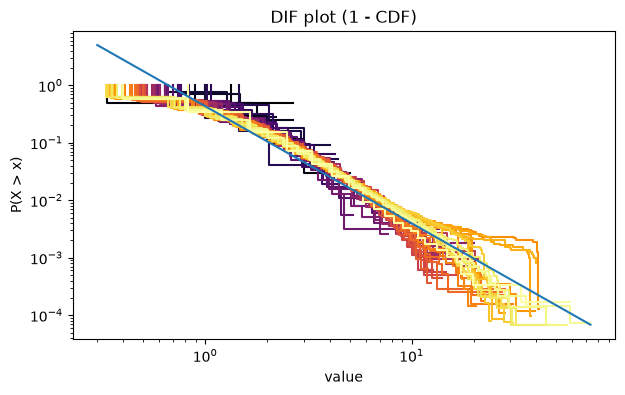

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
cmap1 = plt.get_cmap('inferno')
colors = cmap1(np.linspace(0, 1, len(papers_y)))

for i, (paper, researcher) in enumerate(zip(papers_y, researchers_y)):
    ax.step(paper, researcher, color=colors[i])
ax.plot(x_fit,y_fit)
ax.set_xlabel("value")
ax.set_ylabel("P(X > x)")
ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.set_xscale("log")
ax.set_yscale("log")
plt.show()